## 1. Import libraries

In [1]:
import os, glob, zipfile, random, time
import xml.etree.ElementTree as ET

import numpy as np
import cv2
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# fix the seeds so results can be repeated
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Upload and unzip the dataset



In [2]:
from google.colab import files

uploaded = files.upload()          # pick 150_data_set_v1i_voc.zip
zip_name = list(uploaded.keys())[0]

# --- or, if the zip is in Google Drive: ---
# from google.colab import drive
# drive.mount('/content/drive')
# zip_name = '/content/drive/MyDrive/150_data_set_v1i_voc.zip'

DATA_DIR = "/content/dataset"
with zipfile.ZipFile(zip_name) as z:
    z.extractall(DATA_DIR)

for split in ["train", "valid", "test"]:
    n = len(glob.glob(f"{DATA_DIR}/{split}/*.jpg"))
    print(split, "->", n, "images")

Saving 150 data set.v1i.voc.zip to 150 data set.v1i.voc (1).zip
train -> 175 images
valid -> 49 images
test -> 10 images


## 3. Prepare the dataset



In [3]:
CLASSES = ["background", "Book", "Bottle", "Plate"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
IMG_SIZE = 128          # same size as the tutorial; try 256 later if you have a GPU


def load_sample(img_path):
    """Read one image + its xml and return (resized image, resized mask)."""
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    mask = np.zeros((h, w), dtype=np.uint8)
    xml_path = os.path.splitext(img_path)[0] + ".xml"
    root = ET.parse(xml_path).getroot()
    for obj in root.findall("object"):
        name = obj.find("name").text.strip()
        if name not in CLASS_TO_ID:
            continue
        box = obj.find("bndbox")
        x1, x2 = int(float(box.find("xmin").text)), int(float(box.find("xmax").text))
        y1, y2 = int(float(box.find("ymin").text)), int(float(box.find("ymax").text))
        mask[y1:y2, x1:x2] = CLASS_TO_ID[name]       # fill the box with the class id

    # resize: bilinear for the image, nearest for the mask (so class ids don't get blended)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return img, mask


def load_split(split):
    paths = sorted(glob.glob(f"{DATA_DIR}/{split}/*.jpg"))
    images, masks = [], []
    for p in paths:
        im, mk = load_sample(p)
        images.append(im); masks.append(mk)
    images = np.array(images, dtype=np.float32) / 255.0      # normalize to [0, 1]
    masks = np.array(masks, dtype=np.int64)
    return images, masks


train_images, train_masks = load_split("train")
val_images,   val_masks   = load_split("valid")
test_images,  test_masks  = load_split("test")

print("train:", train_images.shape, train_masks.shape)
print("valid:", val_images.shape,   val_masks.shape)
print("test :", test_images.shape,  test_masks.shape)

train: (175, 128, 128, 3) (175, 128, 128)
valid: (49, 128, 128, 3) (49, 128, 128)
test : (10, 128, 128, 3) (10, 128, 128)


In [4]:
class SegDataset(Dataset):
    def __init__(self, images, masks, augment=False):
        self.images = images
        self.masks = masks
        self.augment = augment

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]          # H, W, 3
        mask = self.masks[idx]          # H, W

        if self.augment and random.random() < 0.5:      # simple horizontal flip
            img = img[:, ::-1]
            mask = mask[:, ::-1]

        img = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1)   # -> 3, H, W
        mask = torch.from_numpy(np.ascontiguousarray(mask))
        return img, mask


BATCH_SIZE = 8
train_loader = DataLoader(SegDataset(train_images, train_masks, augment=True),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(SegDataset(val_images, val_masks), batch_size=BATCH_SIZE)
test_loader  = DataLoader(SegDataset(test_images, test_masks), batch_size=BATCH_SIZE)

### Look at the data first

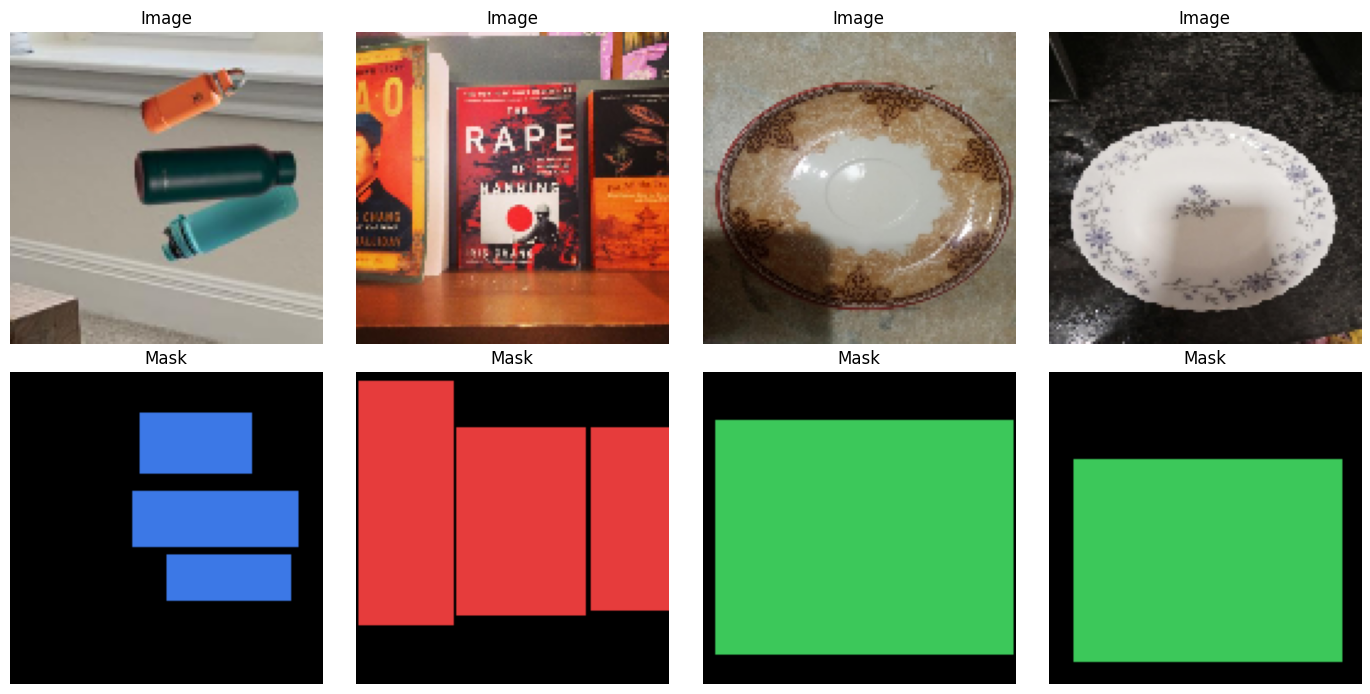

background :  50.4% of pixels
Book       :  19.5% of pixels
Bottle     :   3.9% of pixels
Plate      :  26.2% of pixels


In [5]:
# colours for the 4 classes (just for plotting)
PALETTE = np.array([[0, 0, 0], [230, 60, 60], [60, 120, 230], [60, 200, 90]], dtype=np.uint8)

def colorize(mask):
    return PALETTE[mask]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    axes[0, i].imshow(train_images[i]);          axes[0, i].set_title("Image");  axes[0, i].axis("off")
    axes[1, i].imshow(colorize(train_masks[i])); axes[1, i].set_title("Mask");   axes[1, i].axis("off")
plt.tight_layout(); plt.show()

# class balance (important for choosing a metric)
counts = np.bincount(train_masks.ravel(), minlength=NUM_CLASSES)
for name, c in zip(CLASSES, counts):
    print(f"{name:11s}: {100 * c / counts.sum():5.1f}% of pixels")

## 4. Define the U-Net model




In [6]:
class DoubleConv(nn.Module):
    """Conv -> ReLU -> Conv -> ReLU  (this block repeats everywhere in U-Net)"""
    def __init__(self, in_ch, out_ch, use_bn=False):
        super().__init__()
        layers = [nn.Conv2d(in_ch, out_ch, 3, padding=1)]
        if use_bn: layers.append(nn.BatchNorm2d(out_ch))
        layers.append(nn.ReLU(inplace=True))
        layers.append(nn.Conv2d(out_ch, out_ch, 3, padding=1))
        if use_bn: layers.append(nn.BatchNorm2d(out_ch))
        layers.append(nn.ReLU(inplace=True))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=4, base=64, depth=2, use_bn=False):
        super().__init__()
        # encoder: filters go base, base*2, base*4 ...
        self.encoders = nn.ModuleList()
        self.pool = nn.MaxPool2d(2)
        ch = in_channels
        for d in range(depth):
            self.encoders.append(DoubleConv(ch, base * 2**d, use_bn))
            ch = base * 2**d

        # bottleneck
        self.bottleneck = DoubleConv(ch, base * 2**depth, use_bn)
        ch = base * 2**depth

        # decoder: upsample, concatenate the skip connection, double conv
        self.upsamples = nn.ModuleList()
        self.decoders = nn.ModuleList()
        for d in reversed(range(depth)):
            self.upsamples.append(nn.Upsample(scale_factor=2))      # like UpSampling2D((2,2))
            self.decoders.append(DoubleConv(ch + base * 2**d, base * 2**d, use_bn))
            ch = base * 2**d

        # final 1x1 conv -> one score per class
        self.out_conv = nn.Conv2d(ch, num_classes, kernel_size=1)

    def forward(self, x):
        skips = []
        for enc in self.encoders:
            x = enc(x)
            skips.append(x)          # save for the skip connection
            x = self.pool(x)

        x = self.bottleneck(x)

        for up, dec in zip(self.upsamples, self.decoders):
            x = up(x)
            skip = skips.pop()
            x = torch.cat([x, skip], dim=1)      # like layers.concatenate
            x = dec(x)

        return self.out_conv(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# the tutorial model: depth=2, base=64
model = UNet(num_classes=NUM_CLASSES, base=64, depth=2).to(device)
print(model)
print(f"\nTrainable parameters: {count_params(model):,}")

# quick shape check: output should be (batch, 4, 128, 128)
dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)
print("Output shape:", model(dummy).shape)

UNet(
  (encoders): ModuleList(
    (0): DoubleConv(
      (block): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
    (1): DoubleConv(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottleneck): DoubleConv(
    (block): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (upsamples): ModuleList(
 

## 5. Training and evaluation functions



In [7]:
def compute_iou(pred, target, num_classes=NUM_CLASSES):
    """Per-class intersection and union (skipping background). Returns two arrays."""
    inter = np.zeros(num_classes); union = np.zeros(num_classes)
    for c in range(1, num_classes):
        p = (pred == c); t = (target == c)
        inter[c] = (p & t).sum()
        union[c] = (p | t).sum()
    return inter, union


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    inter = np.zeros(NUM_CLASSES); union = np.zeros(NUM_CLASSES)
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            out = model(imgs)
            total_loss += criterion(out, masks).item() * imgs.size(0)
            pred = out.argmax(dim=1)
            correct += (pred == masks).sum().item()
            total += masks.numel()
            i, u = compute_iou(pred.cpu().numpy(), masks.cpu().numpy())
            inter += i; union += u
    n = len(loader.dataset)
    iou_per_class = inter[1:] / np.maximum(union[1:], 1)
    return total_loss / n, correct / total, iou_per_class.mean()


def train_model(model, lr, epochs=20, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_miou": []}

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), masks)
            loss.backward()
            optimizer.step()
            running += loss.item() * imgs.size(0)

        train_loss = running / len(train_loader.dataset)
        val_loss, val_acc, val_miou = evaluate(model, val_loader, criterion)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_miou"].append(val_miou)

        if verbose and ((epoch + 1) % 5 == 0 or epoch == 0):
            print(f"Epoch {epoch+1:3d}/{epochs} | train loss {train_loss:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.4f} | val mIoU {val_miou:.4f}")
    return history

## 6. Train the baseline model (tutorial architecture, lr = 1e-4)

In [8]:
EPOCHS = 30     # the tutorial used 20; real photos need a bit longer than synthetic rectangles

torch.manual_seed(SEED)
model = UNet(num_classes=NUM_CLASSES, base=64, depth=2).to(device)
history = train_model(model, lr=1e-4, epochs=EPOCHS)

Epoch   1/30 | train loss 1.3711 | val loss 1.2602 | val acc 0.5005 | val mIoU 0.0059
Epoch   5/30 | train loss 1.1599 | val loss 1.1060 | val acc 0.5829 | val mIoU 0.0000
Epoch  10/30 | train loss 1.0646 | val loss 1.0449 | val acc 0.5829 | val mIoU 0.0000
Epoch  15/30 | train loss 1.0236 | val loss 1.0342 | val acc 0.5467 | val mIoU 0.0770
Epoch  20/30 | train loss 1.0028 | val loss 1.0435 | val acc 0.5161 | val mIoU 0.0858
Epoch  25/30 | train loss 0.9694 | val loss 1.0055 | val acc 0.5528 | val mIoU 0.1271
Epoch  30/30 | train loss 0.9595 | val loss 1.0089 | val acc 0.5693 | val mIoU 0.1282


### Evaluate the model

Validation Loss: 1.0089, Validation Accuracy: 0.5693, Validation mIoU: 0.1282
Test       Loss: 0.8482, Test       Accuracy: 0.6443, Test       mIoU: 0.1566


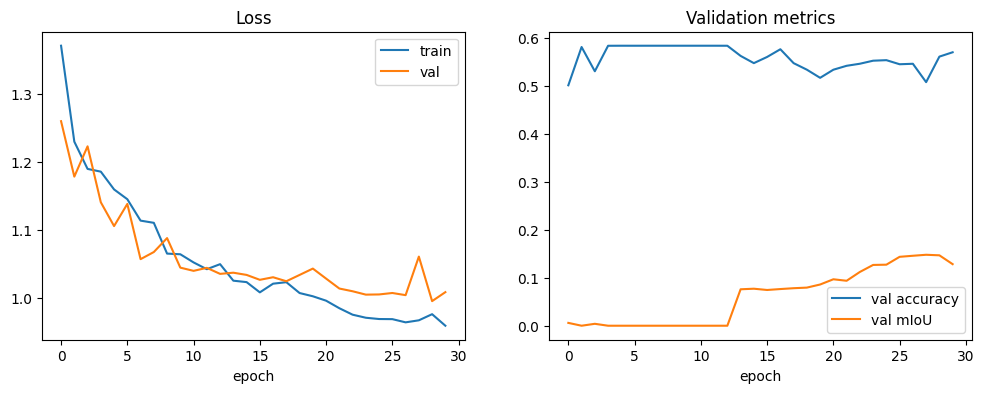

In [9]:
criterion = nn.CrossEntropyLoss()
val_loss, val_acc, val_miou = evaluate(model, val_loader, criterion)
print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}, Validation mIoU: {val_miou:.4f}")

test_loss, test_acc, test_miou = evaluate(model, test_loader, criterion)
print(f"Test       Loss: {test_loss:.4f}, Test       Accuracy: {test_acc:.4f}, Test       mIoU: {test_miou:.4f}")

# training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["val_acc"], label="val accuracy"); ax[1].plot(history["val_miou"], label="val mIoU")
ax[1].set_title("Validation metrics"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

### Visualize predictions

Colours -> red: Book, blue: Bottle, green: Plate, black: background


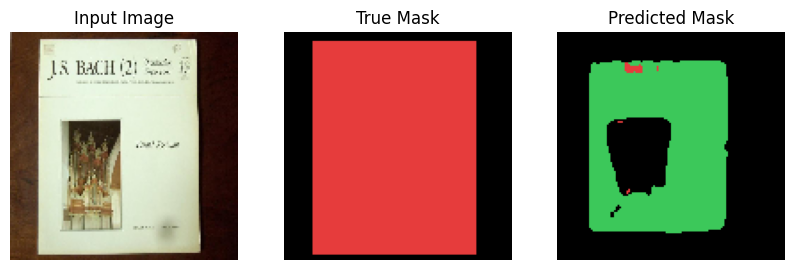

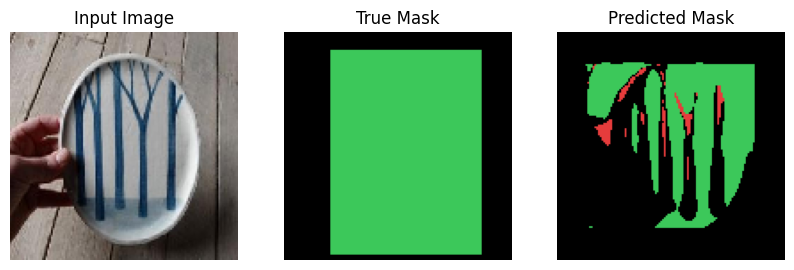

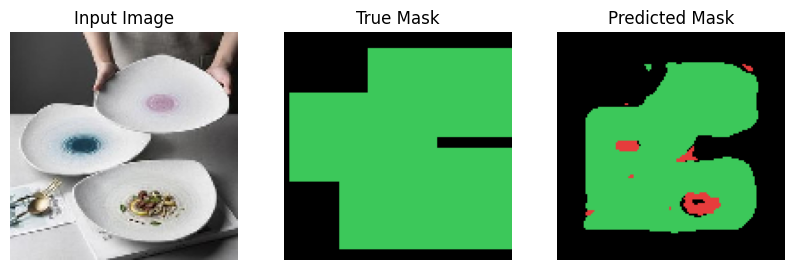

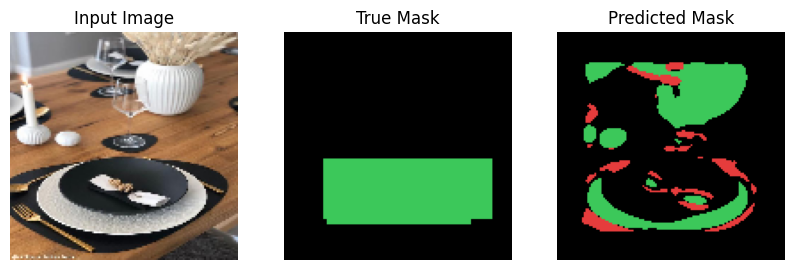

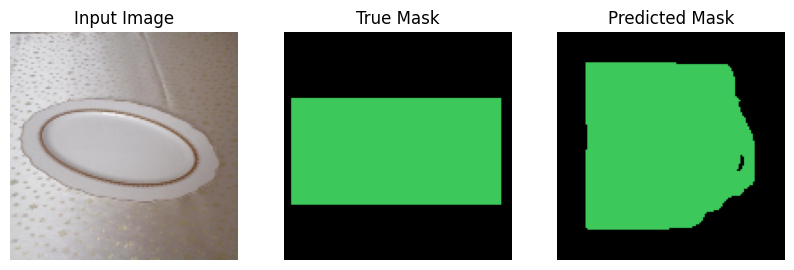

In [10]:
def predict_masks(model, images):
    model.eval()
    x = torch.from_numpy(images).permute(0, 3, 1, 2).to(device)
    with torch.no_grad():
        return model(x).argmax(dim=1).cpu().numpy()


def plot_sample(image, true_mask, pred_mask):
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 3, 1); plt.title("Input Image");     plt.imshow(image);                  plt.axis("off")
    plt.subplot(1, 3, 2); plt.title("True Mask");       plt.imshow(colorize(true_mask));    plt.axis("off")
    plt.subplot(1, 3, 3); plt.title("Predicted Mask");  plt.imshow(colorize(pred_mask));    plt.axis("off")
    plt.show()


pred_masks = predict_masks(model, val_images)
print("Colours -> red: Book, blue: Bottle, green: Plate, black: background")
for i in range(5):      # show 5 examples
    plot_sample(val_images[i], val_masks[i], pred_masks[i])

## Task 2: Change the layers



In [11]:
arch_configs = {
    "Tutorial (d2, b64)":      dict(base=64, depth=2, use_bn=False),
    "Shallow-narrow (d2, b16)": dict(base=16, depth=2, use_bn=False),
    "Deeper (d3, b32)":        dict(base=32, depth=3, use_bn=False),
    "Deeper + BN (d3, b32)":   dict(base=32, depth=3, use_bn=True),
}

arch_results = {}
for name, cfg in arch_configs.items():
    print(f"\n=== {name} ===")
    torch.manual_seed(SEED)
    m = UNet(num_classes=NUM_CLASSES, **cfg).to(device)
    print(f"parameters: {count_params(m):,}")
    t0 = time.time()
    h = train_model(m, lr=1e-4, epochs=EPOCHS)
    arch_results[name] = dict(history=h, model=m, params=count_params(m), time=time.time() - t0)


=== Tutorial (d2, b64) ===
parameters: 1,883,332
Epoch   1/30 | train loss 1.3714 | val loss 1.2629 | val acc 0.4911 | val mIoU 0.0076
Epoch   5/30 | train loss 1.1595 | val loss 1.1049 | val acc 0.5829 | val mIoU 0.0000
Epoch  10/30 | train loss 1.0585 | val loss 1.0430 | val acc 0.5829 | val mIoU 0.0000
Epoch  15/30 | train loss 1.0214 | val loss 1.0310 | val acc 0.5420 | val mIoU 0.0778
Epoch  20/30 | train loss 0.9972 | val loss 1.0373 | val acc 0.5210 | val mIoU 0.0975
Epoch  25/30 | train loss 0.9639 | val loss 1.0033 | val acc 0.5536 | val mIoU 0.1319
Epoch  30/30 | train loss 0.9540 | val loss 1.0095 | val acc 0.5690 | val mIoU 0.1315

=== Shallow-narrow (d2, b16) ===
parameters: 118,324
Epoch   1/30 | train loss 1.4166 | val loss 1.3987 | val acc 0.0581 | val mIoU 0.0194
Epoch   5/30 | train loss 1.2171 | val loss 1.1415 | val acc 0.5829 | val mIoU 0.0000
Epoch  10/30 | train loss 1.1381 | val loss 1.1412 | val acc 0.5829 | val mIoU 0.0000
Epoch  15/30 | train loss 1.1027 | v

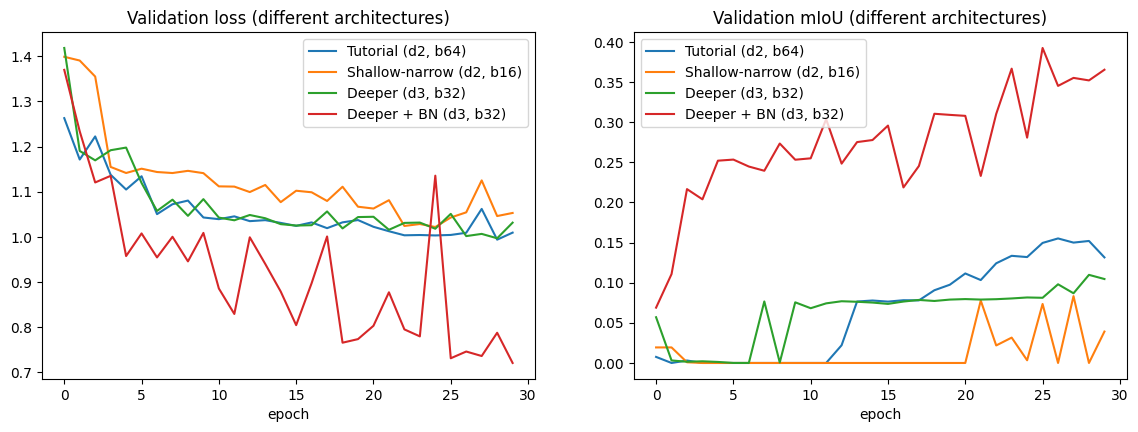

Model                              Params  Time(s)  Val mIoU  Val acc
Tutorial (d2, b64)              1,883,332   5588.4    0.1315   0.5690
Shallow-narrow (d2, b16)          118,324    459.1    0.0391   0.5665
Deeper (d3, b32)                1,946,980   2144.5    0.1046   0.5337
Deeper + BN (d3, b32)           1,949,796   2289.2    0.3653   0.7428


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, r in arch_results.items():
    ax[0].plot(r["history"]["val_loss"], label=name)
    ax[1].plot(r["history"]["val_miou"], label=name)
ax[0].set_title("Validation loss (different architectures)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Validation mIoU (different architectures)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

print(f"{'Model':28s} {'Params':>12s} {'Time(s)':>8s} {'Val mIoU':>9s} {'Val acc':>8s}")
for name, r in arch_results.items():
    h = r["history"]
    print(f"{name:28s} {r['params']:12,d} {r['time']:8.1f} {h['val_miou'][-1]:9.4f} {h['val_acc'][-1]:8.4f}")

## Task 3: Different learning rates



In [13]:
learning_rates = [1e-2, 1e-3, 1e-4, 1e-5]

lr_results = {}
for lr in learning_rates:
    print(f"\n=== learning rate = {lr} ===")
    torch.manual_seed(SEED)
    m = UNet(num_classes=NUM_CLASSES, base=64, depth=2).to(device)
    h = train_model(m, lr=lr, epochs=EPOCHS)
    lr_results[lr] = dict(history=h, model=m)


=== learning rate = 0.01 ===
Epoch   1/30 | train loss 394.3107 | val loss 1.2204 | val acc 0.5644 | val mIoU 0.0011
Epoch   5/30 | train loss 1.1499 | val loss 1.1185 | val acc 0.5829 | val mIoU 0.0000
Epoch  10/30 | train loss 1.1403 | val loss 1.1218 | val acc 0.5829 | val mIoU 0.0000
Epoch  15/30 | train loss 1.1408 | val loss 1.1162 | val acc 0.5829 | val mIoU 0.0000
Epoch  20/30 | train loss 1.1272 | val loss 1.1124 | val acc 0.5829 | val mIoU 0.0000
Epoch  25/30 | train loss 1.1261 | val loss 1.1185 | val acc 0.5829 | val mIoU 0.0000
Epoch  30/30 | train loss 1.1251 | val loss 1.1225 | val acc 0.5829 | val mIoU 0.0000

=== learning rate = 0.001 ===
Epoch   1/30 | train loss 1.3492 | val loss 1.2939 | val acc 0.1880 | val mIoU 0.0627
Epoch   5/30 | train loss 1.1042 | val loss 1.0817 | val acc 0.5829 | val mIoU 0.0000
Epoch  10/30 | train loss 1.0332 | val loss 1.0249 | val acc 0.5612 | val mIoU 0.0723
Epoch  15/30 | train loss 0.9900 | val loss 1.0527 | val acc 0.5283 | val mIo

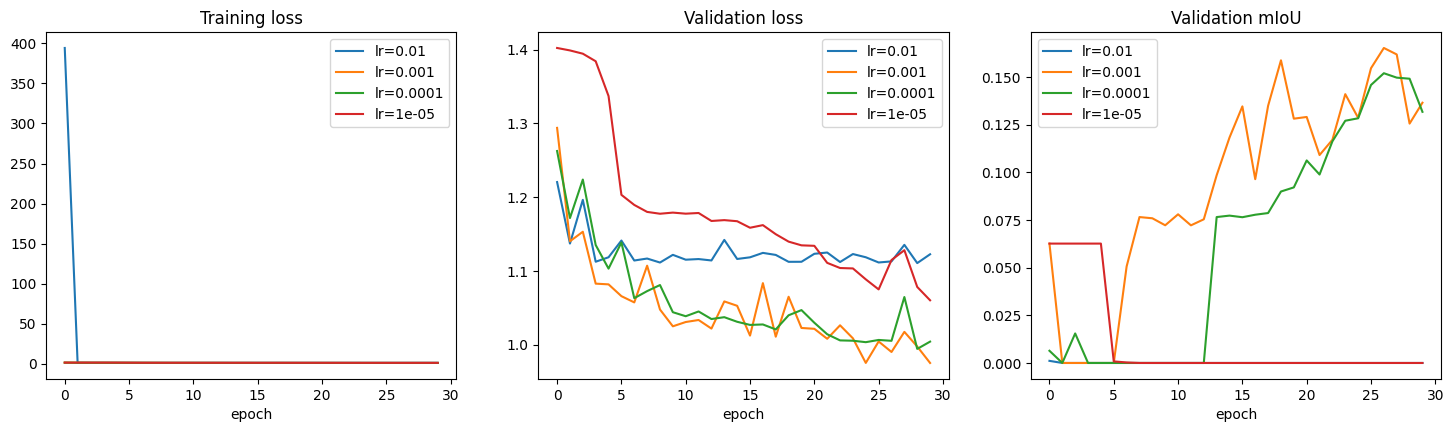

      LR  Final train loss  Final val loss  Val acc  Val mIoU
   1e-02            1.1251          1.1225   0.5829    0.0000
   1e-03            0.9471          0.9752   0.5703    0.1366
   1e-04            0.9549          1.0041   0.5769    0.1318
   1e-05            1.0653          1.0601   0.5829    0.0000


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for lr, r in lr_results.items():
    ax[0].plot(r["history"]["train_loss"], label=f"lr={lr}")
    ax[1].plot(r["history"]["val_loss"],   label=f"lr={lr}")
    ax[2].plot(r["history"]["val_miou"],   label=f"lr={lr}")
ax[0].set_title("Training loss");   ax[1].set_title("Validation loss");   ax[2].set_title("Validation mIoU")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.show()

print(f"{'LR':>8s} {'Final train loss':>17s} {'Final val loss':>15s} {'Val acc':>8s} {'Val mIoU':>9s}")
for lr, r in lr_results.items():
    h = r["history"]
    print(f"{lr:8.0e} {h['train_loss'][-1]:17.4f} {h['val_loss'][-1]:15.4f} {h['val_acc'][-1]:8.4f} {h['val_miou'][-1]:9.4f}")

### Same validation images, predicted by each learning rate

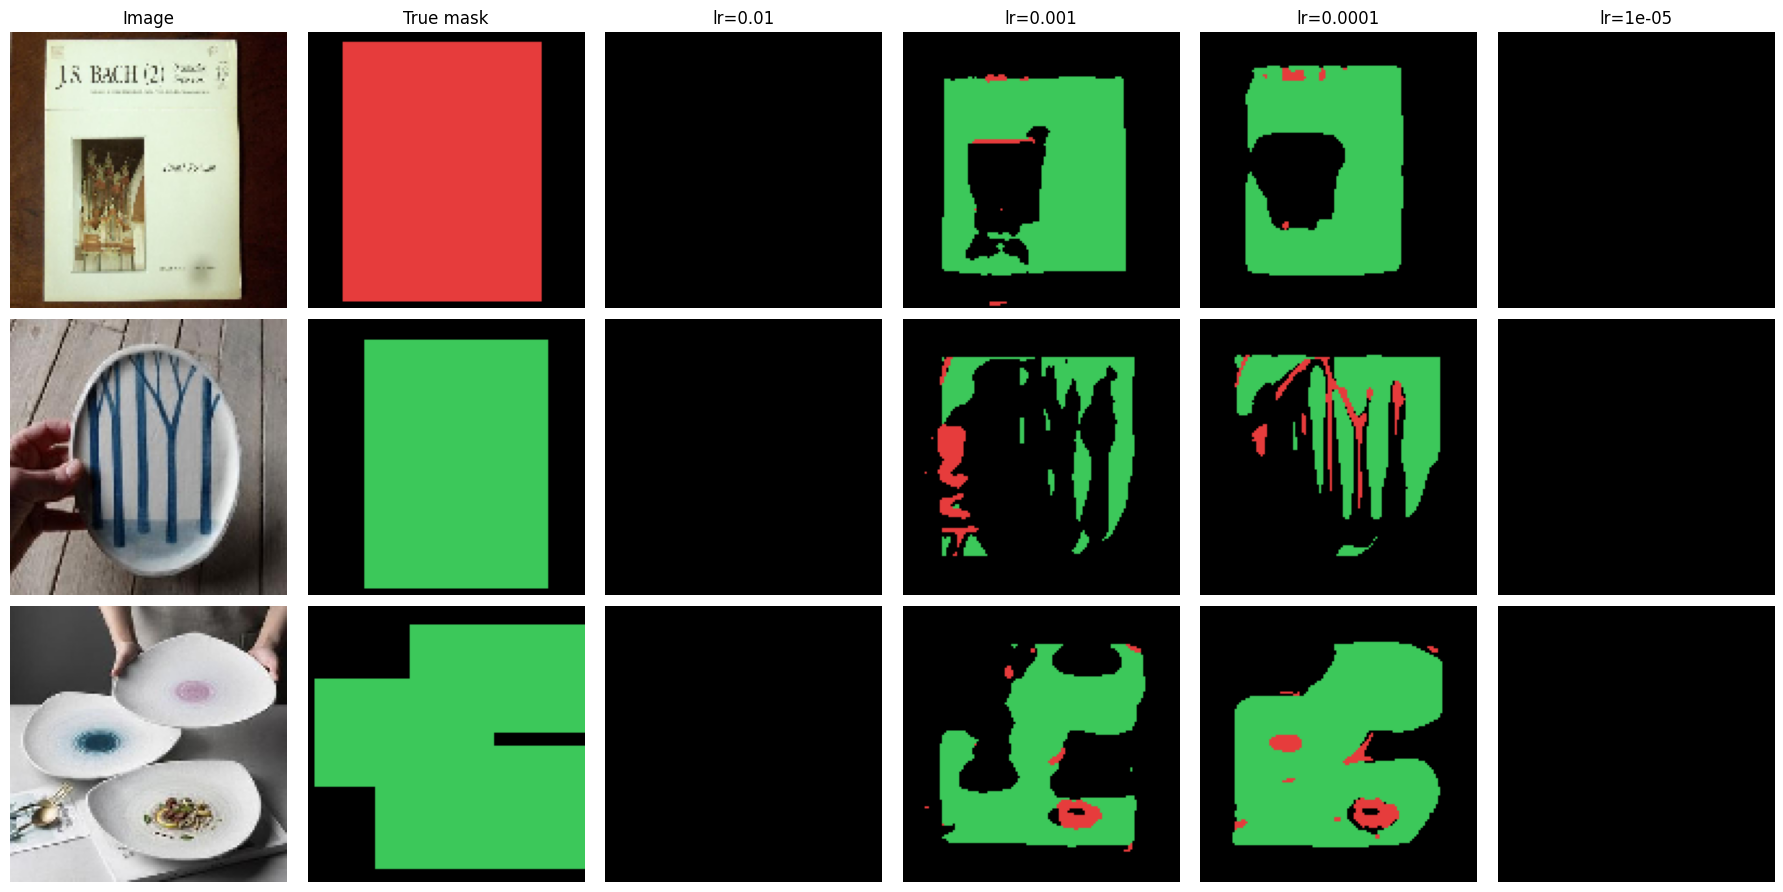

In [15]:
n_show = 3
fig, axes = plt.subplots(n_show, 2 + len(learning_rates), figsize=(3 * (2 + len(learning_rates)), 3 * n_show))
preds_by_lr = {lr: predict_masks(r["model"], val_images[:n_show]) for lr, r in lr_results.items()}

for row in range(n_show):
    axes[row, 0].imshow(val_images[row]);              axes[row, 0].set_title("Image" if row == 0 else "")
    axes[row, 1].imshow(colorize(val_masks[row]));     axes[row, 1].set_title("True mask" if row == 0 else "")
    for j, lr in enumerate(learning_rates):
        axes[row, 2 + j].imshow(colorize(preds_by_lr[lr][row]))
        axes[row, 2 + j].set_title(f"lr={lr}" if row == 0 else "")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## Final test-set check with the best settings



Best learning rate: 0.001
Test loss 0.8684 | Test acc 0.6319 | Test mIoU 0.1437


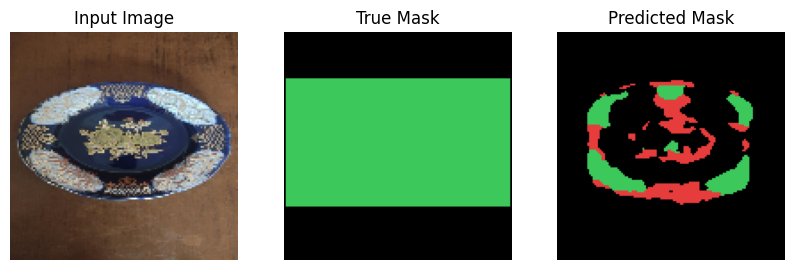

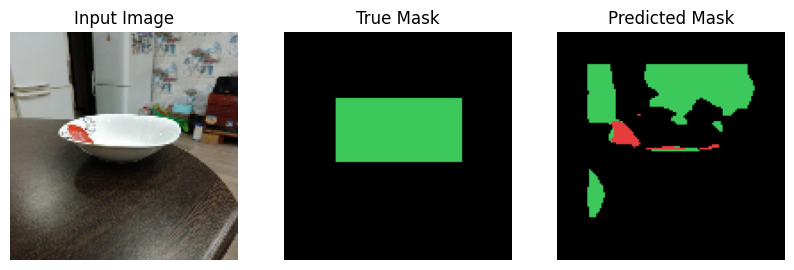

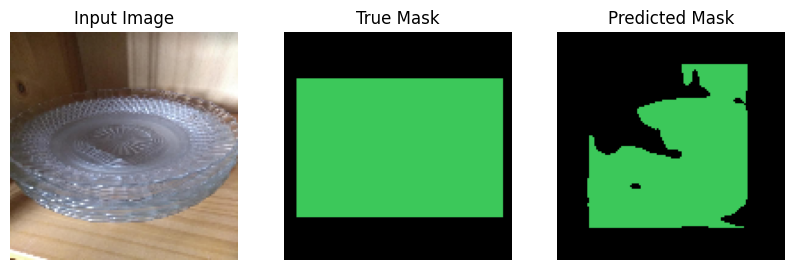

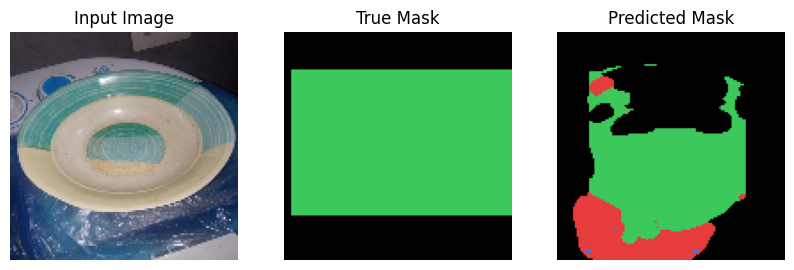

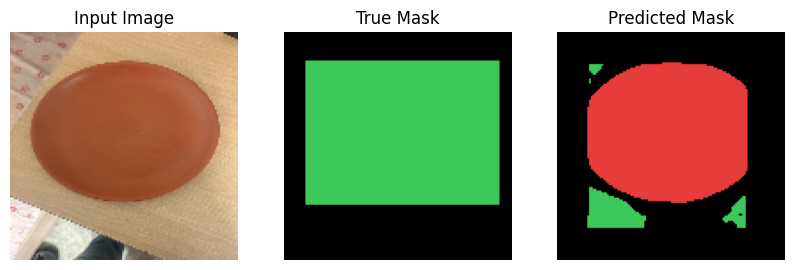

In [16]:
# pick the best learning-rate model by final validation mIoU
best_lr = max(lr_results, key=lambda lr: lr_results[lr]["history"]["val_miou"][-1])
best_model = lr_results[best_lr]["model"]
print("Best learning rate:", best_lr)

t_loss, t_acc, t_miou = evaluate(best_model, test_loader, nn.CrossEntropyLoss())
print(f"Test loss {t_loss:.4f} | Test acc {t_acc:.4f} | Test mIoU {t_miou:.4f}")

test_preds = predict_masks(best_model, test_images)
for i in range(min(5, len(test_images))):
    plot_sample(test_images[i], test_masks[i], test_preds[i])

# save the weights so you don't have to retrain
torch.save(best_model.state_dict(), "unet_best.pth")